# Textual Restoration Tool: final project code

One pipeline for a degraded manuscript page:

1. **Detect** the degradation: **stain**, **blur** or **bleed-through** (or **clean** if none is found).
2. **Restore** the page with the method built for that degradation.

| Degradation | Detection | Restoration | Author |
|---|---|---|---|
| Stain | Paper background that is darker **and** redder (browner) than the page, as large blobs (`is_stain`) | Background division, then CLAHE, then unsharp masking, giving an enhanced greyscale page (`remove_stain`) | Sam |
| Bleed-through | Detector C: intermediate-tone components away from dark ink, weighted by weaker edges (`bleedthrough_features`) | Background normalisation, then Otsu, then edge gate (`binarize`) | Joeal |
| Blur | Laplacian-variance reduction after a further σ = 1 Gaussian blur (`detect_blur_percentage`) | Unsharp masking, strength 3.0, σ 2.5 (`sharpen_unsharp`) | Mohit |

**Routing order: stain, then blur, then bleed-through.** The bleed-through detector is the least specific of the three. It also fires on stained and blurred pages, which Joeal's notebook reports as known confounders. It is therefore checked last, only once stain and blur have been ruled out. Section 5 explains the order and the thresholds.

**Usage:** set `INPUT_PATH` in the next cell and run all cells. Results are written to `OUT_DIR`. Requires only `opencv-python`, `numpy` and `matplotlib`. The scikit-image functions Joeal used (Otsu, multi-Otsu, speck removal) are re-implemented with OpenCV/NumPy.

## 0. Setup

In [1]:
import os, glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---- change this to the image you want to restore ----
# INPUT_PATH = 'Sam/StainImages/Zoernikav folio212.jpg'
INPUT_PATH = 'Sam/StainImages/H05.png'

OUT_DIR = 'final_output'

os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams['figure.dpi'] = 110


def load_image(path):
    # Load any image as 8-bit BGR (greyscale scans are replicated to 3 channels).
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f'Image not found: {path}')
    return img


def to_gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def to_bgr(img):
    return cv2.cvtColor(img, cv2.COLOR_GRAY2BGR) if img.ndim == 2 else img


def show(images, titles=None, cols=2, width=16):
    # Show images in a grid; greyscale uses a fixed 0-255 scale.
    n = len(images)
    rows = (n + cols - 1) // cols
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(width, width / cols * h / w * rows + 0.5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        ax.axis('off')
        if i < n:
            img = images[i]
            if img.ndim == 2:
                ax.imshow(img, cmap='gray', vmin=0, vmax=255)
            else:
                ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            if titles:
                ax.set_title(titles[i], fontsize=10)
    plt.tight_layout(); plt.show()

## 1. Shared helpers

Replacements for the scikit-image functions used in Joeal's code, so the notebook only needs OpenCV and NumPy:

- `luminance`: greyscale conversion with the same weights as `skimage.color.rgb2gray`, in fixed-point arithmetic.
- `threshold_otsu`: global Otsu, like `skimage.filters.threshold_otsu`.
- `multiotsu_3`: three-class Otsu by exhaustive search over the 256-bin histogram. It returns thresholds `(low, high)` with the same class convention as `skimage.filters.threshold_multiotsu`: `<= low`, `(low, high]`, `> high`.
- `remove_specks`: removes 4-connected components of `max_size` pixels or fewer, like `skimage.morphology.remove_small_objects`.

In [2]:
def luminance(image):
    """Convert an OpenCV-order colour array to 8-bit grayscale."""
    if image.ndim == 2:
        return image
    blue, green, red = np.moveaxis(image.astype(np.int32), -1, 0)
    return ((3735 * blue + 19235 * green + 9798 * red + 16384) >> 15).astype(np.uint8)


def _groups(image):
    counts = np.bincount(image.ravel(), minlength=256)
    levels = np.flatnonzero(counts)
    counts = counts[levels]
    weight = np.r_[0, np.cumsum(counts, dtype=np.float64)]
    moment = np.r_[0, np.cumsum(counts * levels, dtype=np.float64)]
    return levels, weight, moment


def threshold_otsu(image):
    """Pick the split that maximises the weighted separation of two groups."""
    levels, weight, moment = _groups(image)
    if len(levels) == 1:
        return int(levels[0])

    left = weight[1:-1]
    right = weight[-1] - left
    left_mean = moment[1:-1] / left
    right_mean = (moment[-1] - moment[1:-1]) / right
    separation = left * right * (left_mean - right_mean) ** 2
    return int(levels[np.argmax(separation)])


def multiotsu_3(gray):
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    levels = np.arange(256)
    w, m = np.cumsum(p), np.cumsum(p * levels)
    i, j = levels[:, None], levels[None, :]
    w0, m0 = w[i], m[i]
    w1, m1 = w[j] - w[i], m[j] - m[i]
    w2, m2 = 1 - w[j], m[-1] - m[j]
    with np.errstate(divide='ignore', invalid='ignore'):
        between = m0 ** 2 / w0 + m1 ** 2 / w1 + m2 ** 2 / w2   # maximise between-class variance
    between[~np.isfinite(between)] = -1
    between[np.tril_indices(256)] = -1                          # require low < high
    low, high = np.unravel_index(np.argmax(between), between.shape)
    return int(low), int(high)


def remove_specks(mask, max_size):
    """Keep 4-connected foreground components larger than max_size."""
    _, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=4)
    keep = stats[:, cv2.CC_STAT_AREA] > max_size
    keep[0] = False
    return keep[labels]

## 2. Stain (Sam)

### 2.1 Detection: `is_stain`

A stain is a large patch of paper that is **darker and redder (browner)** than the typical page. Shadows and dark edges are darker but not redder, so they are ignored.

1. Shrink to ~300 px for speed.
2. Estimate the paper: dilation erases ink and bleed-through, and a median blur smooths the result.
3. In LAB space, mark pixels with L below the page median by more than `dark` (8%) **and** `a*` (red-green) above the median by more than `min_red`.
4. Keep only blobs of at least 0.5% of the page. The stained fraction is their total area.

In [3]:
def is_stain(image, dark=0.08, min_red=1.8, min_area=0.01):
    # Returns (is_stained, stained_fraction_of_page).
    image = to_bgr(image)
    s = min(1.0, 300 / max(image.shape[:2]))
    small = cv2.resize(image, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    w = small.shape[1]

    # Paper background: dilate erases ink / bleed-through, median blur smooths
    k = max(3, int(w * 0.006) | 1)
    window = max(3, int(w * 0.04) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    bg = cv2.medianBlur(cv2.dilate(small, kernel), window)

    # Darker and redder than the typical paper
    lab = cv2.cvtColor(bg, cv2.COLOR_BGR2LAB).astype(np.float32)
    L, a = lab[:, :, 0], lab[:, :, 1]
    mask = (L < np.median(L) * (1 - dark)) & (a - np.median(a) > min_red)
    mask = cv2.morphologyEx(mask.astype(np.uint8) * 255, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

    # Keep only large blobs
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    areas = stats[1:, cv2.CC_STAT_AREA]
    stain_fraction = areas[areas >= 0.005 * mask.size].sum() / mask.size
    return bool(stain_fraction > min_area), float(stain_fraction)

### 2.2 Restoration: background division, CLAHE, unsharp masking

The output is an **enhanced greyscale page**, not a binary one. Binarisation was tried and dropped, because it made handwritten strokes either too bold or too faint.

1. **Shadow and stain removal (`remove_shadow`):** a dilation wider than the pen strokes erases the ink, and a median blur (about 4% of the page width) smooths what is left into an estimate of the paper, stain included. Dividing the page by this estimate flattens the stain and the lighting while keeping the ink.
2. **CLAHE** (clip limit 3.0, 16×16 tiles) restores local contrast in the flattened page.
3. **Unsharp masking** (σ = 1.0, weights 1.6 / −0.6) crisps the strokes.

Both kernel sizes scale with the page width, so the same settings work on a 1200 px scan and on a 3000 px one.

In [4]:
def remove_shadow(gray: np.ndarray, window: int | None = None, k: int | None = None) -> np.ndarray:
    """Erase ink with dilation, estimate the paper, divide it out."""
    if window is None:
        window = max(3, int(gray.shape[1] * 0.04) | 1)   # ~4% of width, always odd
    if k is None:
        k = max(3, int(gray.shape[1] * 0.006) | 1)        # wider than strokes, always odd

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    dilated = cv2.dilate(gray, kernel)
    background = cv2.medianBlur(dilated, window)
    background = np.maximum(background, 1)

    norm = cv2.divide(gray, background, scale=255)
    return np.clip(norm, 0, 255).astype(np.uint8)


def process_image(image: np.ndarray, window: int | None = None, k: int | None = None) -> np.ndarray:
    """Grayscale -> shadow/stain removal -> CLAHE -> sharpening. Returns a greyscale page."""
    if image is None or image.size == 0:
        raise ValueError("The input image is empty.")

    gray = to_gray(image)

    norm = remove_shadow(gray, window=window, k=k)

    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(16, 16))
    enhanced = clahe.apply(norm)

    blur = cv2.GaussianBlur(enhanced, (0, 0), sigmaX=1.0)
    return cv2.addWeighted(enhanced, 1.6, blur, -0.6, 0)


def remove_stain(image):
    return dict(output=process_image(image), method='remove_shadow + CLAHE + unsharp')

## 3. Bleed-through (Joeal)

### 3.1 Detection: `bleedthrough_features` (detector C)

Bleed-through is ink seen **through** the paper, so it is lighter and softer than front-side ink.

1. Downscale to ≤1200 px and divide out a broad illumination estimate (ink erased by dilation, then a wide Gaussian). This copy is used for analysis only.
2. Three-class Otsu splits the page into dark (front ink), middle (candidate ghost ink) and bright (paper).
3. Middle-class components **away from** the dark ink, of plausible text size and shape, are candidates.
4. Each candidate is weighted by how much **weaker its edges** are than the front ink's edges.
5. Score = weighted candidate area / front-ink area. The page counts only if the evidence is credible: at least 3 components and at least 0.1% of the page.

The score is **not** a probability. Section 5 gives the cutoff.

In [5]:
def bleedthrough_features(image, score_threshold=0.10, max_side=1200):
    gray = luminance(image)
    s = min(1.0, max_side / max(gray.shape))
    if s < 1:
        gray = cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    h, w = gray.shape
    page = h * w

    # 1. Flatten the illumination: dilation erases ink, a wide Gaussian smooths
    k = max(3, int(max(h, w) * 0.01) | 1)
    paper = cv2.dilate(gray, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    paper = cv2.GaussianBlur(paper.astype(np.float32), (0, 0), max(h, w) / 40)
    flat = np.clip(gray / np.maximum(paper, 1) * 255, 0, 255).astype(np.uint8)

    # 2. Three classes: front ink / candidate ghost ink / paper
    low, high = multiotsu_3(flat)
    dark = remove_specks(flat <= low, 4)
    mid = (flat > low) & (flat <= high)
    dark_area = int(dark.sum())
    empty = dict(detected=False, score=0.0, credible=False, num_components=0,
                 candidate_fraction=0.0, thresholds=(low, high))
    if dark_area == 0:
        return empty

    # 3. Candidates: middle-tone components away from the front ink
    gap = max(3, int(round(min(h, w) * 0.004)))
    near_ink = cv2.dilate(dark.astype(np.uint8),
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * gap + 1, 2 * gap + 1))) > 0
    cand = (mid & ~near_ink).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(cand, connectivity=8)
    area = stats[:, cv2.CC_STAT_AREA].astype(np.float64)
    bw, bh = stats[:, cv2.CC_STAT_WIDTH], stats[:, cv2.CC_STAT_HEIGHT]
    elong = np.maximum(bw, bh) / np.maximum(np.minimum(bw, bh), 1)
    fill = area / np.maximum(bw * bh, 1)
    plausible = (area >= max(15, page * 2e-5)) & (area <= page * 0.01) & (elong <= 15) & (fill >= 0.1)
    plausible[0] = False
    if not plausible.any():
        return empty

    # 4. Edge strength: candidates vs front ink (Sobel magnitude on component boundaries)
    f = flat.astype(np.float32)
    mag = cv2.magnitude(cv2.Sobel(f, cv2.CV_32F, 1, 0), cv2.Sobel(f, cv2.CV_32F, 0, 1))
    k3 = np.ones((3, 3), np.uint8)
    dark_u8 = dark.astype(np.uint8)
    dark_edge = (dark_u8 > 0) & (cv2.erode(dark_u8, k3) == 0)
    front_edge = float(mag[dark_edge].mean()) if dark_edge.any() else 0.0
    if front_edge <= 0:
        return empty

    kept = plausible[lab]
    boundary = kept & (cv2.erode(kept.astype(np.uint8), k3) == 0)
    edge_sum = np.bincount(lab[boundary], weights=mag[boundary], minlength=n)
    edge_cnt = np.bincount(lab[boundary], minlength=n)
    cand_edge = edge_sum / np.maximum(edge_cnt, 1)
    weight = np.clip(1 - cand_edge / front_edge, 0, 1)

    # 5. Score and credibility
    score = float((weight * area)[plausible].sum() / dark_area)
    num = int(plausible.sum())
    cand_fraction = float(area[plausible].sum() / page)
    credible = num >= 3 and cand_fraction >= 0.001
    return dict(detected=bool(credible and score >= score_threshold), score=score, credible=credible,
                num_components=num, candidate_fraction=cand_fraction, thresholds=(low, high))

### 3.2 Restoration: background normalisation, then Otsu, then edge gate

1. **Background normalisation:** a 31 px closing erases the strokes, and a 21 px median smooths the result. Dividing the page by this background estimate flattens stains, yellowing and lighting.
2. **Otsu + speck removal:** once the page is flattened, front ink is the darkest thing on it. Blobs of 30 px or fewer are removed.
3. **Edge gate:** Canny edges are computed on the original. A blob is kept only if more than 8% of its pixels are edges. Ghost ink seen through the paper is soft, and real ink is sharp.

On the nine DIBCO pages this scored mean F 90.7, pF 94.7 and DRD 2.57, and never went below F 85.1 (Joeal's `DIBCO_bleedthrough_eval.ipynb`). The output is binary, with ink black and background white.

In [6]:
PARAMS = dict(
    close_size=31,       # step 1: closing kernel, larger than any stroke width
    median_size=21,      # step 1: smooths the background estimate
    min_speck=30,        # step 2: components of this many pixels or fewer are removed
    canny=(60, 150),     # step 3: Canny thresholds on the original image
    min_edge_ratio=0.08, # step 3: edge pixels / component size needed to count as real ink
)


def bg_normalise(gray, close_size, median_size):
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_size, close_size))
    background = cv2.medianBlur(cv2.morphologyEx(gray, cv2.MORPH_CLOSE, se), median_size)
    norm = np.clip(gray.astype(float) / np.maximum(background, 1) * 255, 0, 255).astype(np.uint8)
    return norm, background


def edge_gate(binary, gray, canny, min_edge_ratio):
    edges = cv2.Canny(cv2.GaussianBlur(gray, (3, 3), 0), *canny) > 0
    nl, lab = cv2.connectedComponents(binary.astype(np.uint8), connectivity=8)
    edge_cnt = np.bincount(lab[edges], minlength=nl)
    size = np.bincount(lab.ravel(), minlength=nl)
    keep = edge_cnt / np.maximum(size, 1) > min_edge_ratio
    keep[0] = False                                   # label 0 is background
    return keep[lab], edges


def binarize(gray, p=PARAMS):
    norm, background = bg_normalise(gray, p['close_size'], p['median_size'])          # step 1
    t = threshold_otsu(norm)
    thresh = remove_specks(norm < t, p['min_speck'])                                   # step 2
    final, edges = edge_gate(thresh, gray, p['canny'], p['min_edge_ratio'])           # step 3
    return final, dict(background=background, normalised=norm, otsu_t=t,
                       thresholded=thresh, edges=edges, removed_by_gate=thresh & ~final)


def remove_bleedthrough(image):
    mask, steps = binarize(luminance(image))
    return dict(
        output=np.where(mask, 0, 255).astype(np.uint8),   # ink black on white
        method='bg normalisation + Otsu + edge gate',
        steps=steps,
    )

## 4. Blur (Mohit)

### 4.1 Restoration: three sharpening methods

Mohit compared three ways of sharpening a blurred page:

- **Unsharp masking** (`sharpen_unsharp`): `(1 + strength)·image − strength·GaussianBlur(image, σ)`, with strength 3.0 and σ 2.5. **This is the method the pipeline uses.**
- **Laplacian sharpening** (`sharpen_laplacian`): subtracts `strength` × the Laplacian (0.5 by default; Mohit's comparison uses 1.5).
- **CLAHE + unsharp** (`sharpen_clahe`): local contrast (clip 2.0, 8×8 tiles), then unsharp masking with strength 3 and σ 1.0.

`enhance_text(image, method=...)` picks one by name. Non-blind Wiener deconvolution needs the true blur kernel, which is unknown for a real scan, so it is not used.

In [7]:
def sharpen_unsharp(image, strength=3.0, sigma=2.5):
    smooth = cv2.GaussianBlur(image, (0, 0), sigma)
    return cv2.addWeighted(image, 1 + strength, smooth, -strength, 0)


def sharpen_laplacian(image, strength=0.5):
    laplacian = cv2.Laplacian(image, cv2.CV_32F)
    sharpened = image.astype(np.float32) - strength * laplacian
    return np.uint8(np.clip(sharpened, 0, 255))


def sharpen_clahe(image):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return sharpen_unsharp(clahe.apply(image), strength=3, sigma=1.0)


def enhance_text(image, method='unsharp'):
    methods = dict(unsharp=sharpen_unsharp, laplacian=sharpen_laplacian, clahe=sharpen_clahe)
    if method not in methods:
        raise ValueError('Unknown sharpening method')
    return methods[method](to_gray(image))


def remove_blur(image, method='unsharp'):
    names = dict(unsharp='Unsharp masking (strength 3.0, sigma 2.5)',
                 laplacian='Laplacian sharpening (strength 0.5)',
                 clahe='CLAHE + unsharp masking')
    return dict(output=enhance_text(image, method), method=names[method])

### 4.2 Detection: `detect_blur_percentage`

The variance of the Laplacian measures how much fine detail an image has. A sharp page loses most of that variance when it is blurred **a little more** (σ = 1). A page that is already blurred has little left to lose.

- reduction = (var_before − var_after) / var_before × 100
- **reduction < 45% means blurred.** This is the cutoff in Mohit's `process_image`.

This relative measure is used instead of the raw Laplacian variance (`detect_blur`, threshold 100 or 40), because the raw value depends on resolution and on how much text is on the page. Both values are reported.

**Known limit:** the detector is tuned to Gaussian (soft-focus) blur. On a test page, Gaussian σ ≥ 2 is caught, but **horizontal motion blur is not caught at any length** (reduction stays around 84%, because detail across the motion direction survives), and defocus is borderline (radius 5 is caught, radius 7 is not). Run `blur_detector_check` in section 8 on your own pages to see the numbers.

`blur_auto(image, mode)` is Mohit's `process_image` (renamed, because section 2 already has a `process_image` for stains): `'auto'` sharpens only if blur is detected, `'always'` always sharpens, and `'never'` returns the page unchanged.

In [8]:
def detect_blur(gray, threshold=100):
    score = cv2.Laplacian(to_gray(gray), cv2.CV_64F).var()
    return bool(score < threshold), float(score)


def detect_blur_percentage(gray, sigma=1):
    gray = to_gray(gray)
    original_score = cv2.Laplacian(gray, cv2.CV_64F).var()
    blurred_score = cv2.Laplacian(cv2.GaussianBlur(gray, (0, 0), sigmaX=sigma), cv2.CV_64F).var()
    reduction = (original_score - blurred_score) / max(original_score, 1e-10) * 100
    return float(reduction), float(original_score), float(blurred_score)


def blur_auto(image, mode='auto', max_reduction=45):
    # Mohit's process_image
    if mode == 'always':
        return sharpen_unsharp(to_gray(image))
    if mode == 'never':
        return to_gray(image).copy()
    if mode == 'auto':
        reduction, _, _ = detect_blur_percentage(image)
        return sharpen_unsharp(to_gray(image)) if reduction < max_reduction else to_gray(image).copy()
    raise ValueError('Mode must be auto, always, or never')

### 4.3 Test blurs: Gaussian, motion and defocus

Mohit's test kernels for checking the detector and the sharpeners on a sharp page:

- `create_motion_blur(image, length)`: horizontal line kernel.
- `create_defocus_blur(image, radius)`: uniform disc kernel.

`blur_detector_check(image)` prints the reduction for Gaussian σ 0–5, motion lengths 5–20 and defocus radii 2–7, so you can see where the 45% cutoff falls on your own pages. `blur_psnr_check(image)` blurs a sharp page (σ = 2.5 and σ = 5, as in Mohit's tests) and reports PSNR against the original for each sharpener (higher is closer to the sharp page).

In [9]:
def create_motion_blur(image, length=15):
    kernel = np.zeros((length, length))
    kernel[length // 2, :] = 1
    kernel /= kernel.sum()
    return cv2.filter2D(image, -1, kernel)


def create_defocus_blur(image, radius=5):
    size = 2 * radius + 1
    kernel = np.zeros((size, size), np.float32)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)
    kernel /= kernel.sum()
    return cv2.filter2D(image, -1, kernel)


def blur_detector_check(image, cutoff=45):
    gray = to_gray(image)
    tests = [('sharp', gray)]
    tests += [(f'gaussian sigma={s}', cv2.GaussianBlur(gray, (0, 0), s)) for s in (1, 2, 3, 4, 5)]
    tests += [(f'motion length={n}', create_motion_blur(gray, n)) for n in (5, 10, 15, 20)]
    tests += [(f'defocus radius={r}', create_defocus_blur(gray, r)) for r in (2, 3, 5, 7)]
    print(f"{'test':22s} {'reduction':>10s} {'raw var':>9s}  blurred?")
    for name, t in tests:
        reduction, var, _ = detect_blur_percentage(t)
        print(f"{name:22s} {reduction:9.1f}% {var:9.1f}  {'YES' if reduction < cutoff else 'no'}")


def blur_psnr_check(image, sigmas=(2.5, 5)):
    sharp = to_gray(image)
    for sigma in sigmas:
        blurred = cv2.GaussianBlur(sharp, (0, 0), sigmaX=sigma)
        print(f'PSNR against the sharp page (Gaussian blur sigma={sigma}):')
        for name, out in [('blurred input', blurred), ('unsharp', sharpen_unsharp(blurred)),
                          ('laplacian (1.5)', sharpen_laplacian(blurred, strength=1.5)),
                          ('CLAHE + unsharp', sharpen_clahe(blurred))]:
            print(f'  {name:16s} {cv2.PSNR(sharp, out):6.2f} dB')

## 5. Classifier: which degradation is it?

All three detectors run on every image. Their evidence is reported, and the **first** one that fires, in this order, decides the label:

1. **Stain.** Its evidence is colour plus a large area, measured on a heavily smoothed background. Blur does not affect it, and grey bleed-through on paper does not trigger it.
2. **Blur.** Its evidence is relative loss of detail, which does not depend on stains or ghost ink.
3. **Bleed-through.** Its evidence is mid-tone, soft-edged components. Stains and blur produce the same kind of evidence, so it is only trusted once both have been ruled out.
4. Otherwise the page is **clean** and returned unchanged.

**Thresholds.**

| Detector | Original cutoff | Used here | Why |
|---|---|---|---|
| Stain fraction | 0.01 (Sam) | **0.05** | Real stains score 0.15–0.23. With 0.01, bleed-through page H07 (0.019) was wrongly routed to stain removal. |
| Blur reduction | 45% (Mohit) | **45%** | Sharp pages score 50–95%, σ = 2 blur scores 20–41% and σ = 4 scores 2–9%. Check your own pages with `blur_detector_check` in section 4.3. |
| Bleed-through score | 0.04 (Joeal) | **0.10** | Joeal's 0.04 flagged clean pages. **Check this value** with the batch table in section 8: `bleedthrough_features` here is re-implemented from the description of detector C, so its scores may not match Joeal's `real_detection_scores.csv`. |

These thresholds were chosen on a small set of sample images, so they are engineering choices, not validated accuracy. Change them in `THRESHOLDS`.

In [10]:
THRESHOLDS = dict(
    stain_min_fraction=0.05,      # Sam's is_stain(min_area); his default was 0.01
    bleed_min_score=0.10,         # Joeal's detector C cutoff; his exploratory value was 0.04
    blur_max_reduction=45.0,      # Mohit's process_image cutoff
)


def classify_degradation(image, thresholds=THRESHOLDS):
    # Run every detector and return the label plus every piece of evidence.
    stained, stain_fraction = is_stain(image, min_area=thresholds['stain_min_fraction'])
    bt = bleedthrough_features(image, score_threshold=thresholds['bleed_min_score'])
    reduction, lap_var, _ = detect_blur_percentage(image)
    blurred = reduction < thresholds['blur_max_reduction']

    if stained:
        label = 'stain'
    elif blurred:
        label = 'blur'
    elif bt['detected']:
        label = 'bleed-through'
    else:
        label = 'clean'

    return dict(
        label=label,
        stain=dict(detected=stained, fraction=stain_fraction),
        blur=dict(detected=blurred, reduction_pct=reduction, laplacian_var=lap_var),
        bleed=dict(detected=bt['detected'], score=bt['score'], credible=bt['credible'],
                   components=bt['num_components']),
    )


def print_report(name, c, thresholds=THRESHOLDS):
    s, b, t = c['stain'], c['blur'], c['bleed']
    print(f"{name}\n  -> detected: {c['label'].upper()}")
    print(f"     stain         {'YES' if s['detected'] else 'no ':3}  stained fraction = {s['fraction']:.3f}"
          f"  (>= {thresholds['stain_min_fraction']})")
    print(f"     blur          {'YES' if b['detected'] else 'no ':3}  Laplacian reduction = {b['reduction_pct']:.1f}%"
          f"  (< {thresholds['blur_max_reduction']}%)   raw Laplacian var = {b['laplacian_var']:.1f}")
    print(f"     bleed-through {'YES' if t['detected'] else 'no ':3}  score = {t['score']:.3f}"
          f"  (>= {thresholds['bleed_min_score']}, credible={t['credible']}, {t['components']} components)")

## 6. Detect, then restore

`restore_document()` classifies the page and applies **only** the matching method. A clean page is returned unchanged.

In [11]:
RESTORERS = {
    'stain': remove_stain,                 # Sam
    'bleed-through': remove_bleedthrough,  # Joeal
    'blur': remove_blur,                   # Mohit
}


def restore_document(image, thresholds=THRESHOLDS):
    c = classify_degradation(image, thresholds)
    if c['label'] == 'clean':
        result = dict(output=image.copy(), method='none (no degradation detected)')
    else:
        result = RESTORERS[c['label']](image)
    result['classification'] = c
    return result


def save_result(path, result, out_dir=OUT_DIR):
    stem = os.path.splitext(os.path.basename(path))[0]
    label = result['classification']['label'].replace('-', '')
    out_path = os.path.join(out_dir, f'{stem}_{label}_restored.png')
    cv2.imwrite(out_path, result['output'])
    return out_path

## 7. Run on `INPUT_PATH`

Sam/StainImages/H05.png
  -> detected: BLEED-THROUGH
     stain         no   stained fraction = 0.000  (>= 0.05)
     blur          no   Laplacian reduction = 81.1%  (< 45.0%)   raw Laplacian var = 334.8
     bleed-through YES  score = 1.146  (>= 0.1, credible=True, 128 components)
  -> method applied: bg normalisation + Otsu + edge gate
  -> saved: final_output\H05_bleedthrough_restored.png


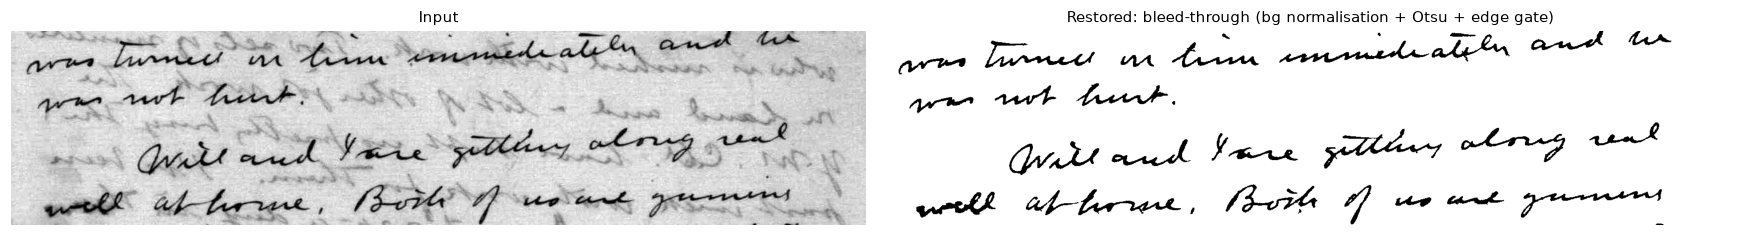

In [12]:
image = load_image(INPUT_PATH)
result = restore_document(image)

print_report(INPUT_PATH, result['classification'])
print(f"  -> method applied: {result['method']}")
print(f"  -> saved: {save_result(INPUT_PATH, result)}")

label = result['classification']['label']
show([image, result['output']], ['Input', f'Restored: {label} ({result["method"]})'], cols=2, width=16)

## 8. Demonstration: one image per route

Sample images that are already in the repository:

- `Sam/StainImages/Zoernikav folio212.jpg`: a stained folio, which should route to **stain**.
- `Sam/StainImages/H05.png`: H-DIBCO 2010 bleed-through, which should route to **bleed-through**.
- `Sam/StainImages/notstainedimageZoernikav.jpeg`: an unstained page, which should be **clean**.
- The same unstained page blurred with a Gaussian of σ = 3, which should route to **blur**. This copy is made in code.

The last cell runs Mohit's blur checks (section 4.3) on the unstained page.

Stained folio (folio212)
  -> detected: STAIN
     stain         YES  stained fraction = 0.231  (>= 0.05)
     blur          no   Laplacian reduction = 75.0%  (< 45.0%)   raw Laplacian var = 305.4
     bleed-through no   score = 0.082  (>= 0.1, credible=True, 231 components)
  -> method applied: remove_shadow + CLAHE + unsharp



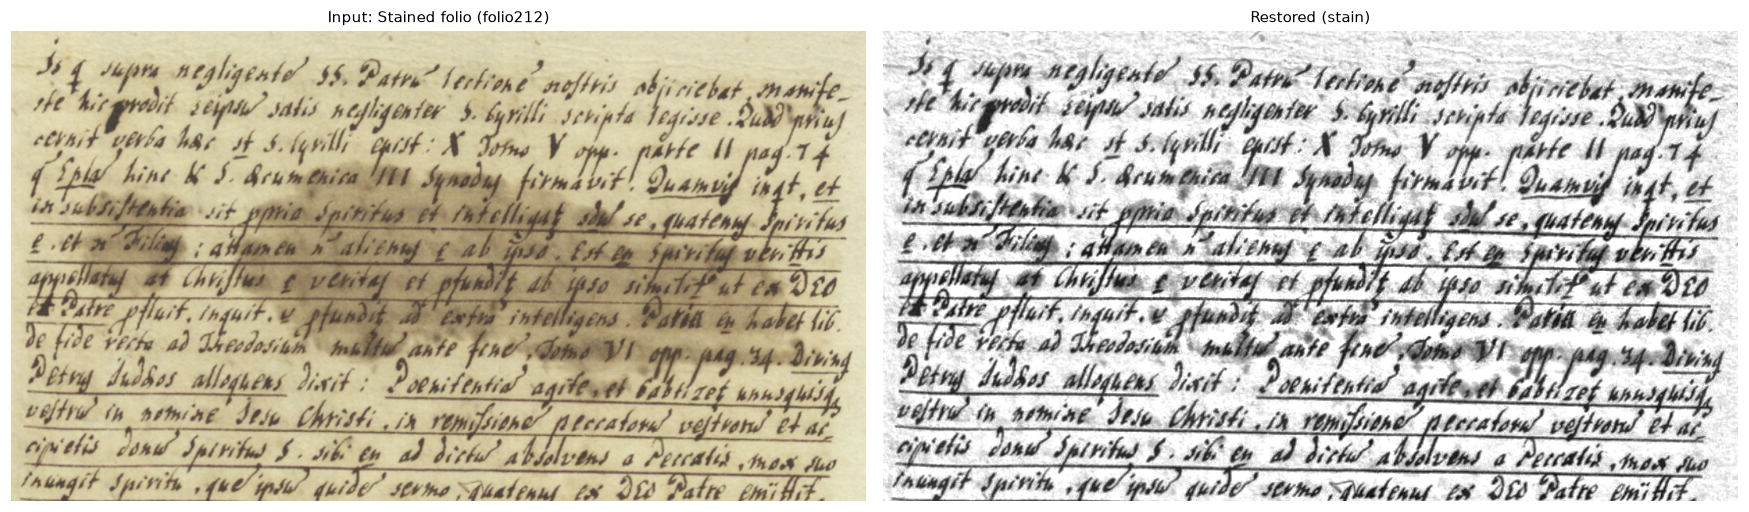

Bleed-through (H-DIBCO 2010 H05)
  -> detected: BLEED-THROUGH
     stain         no   stained fraction = 0.000  (>= 0.05)
     blur          no   Laplacian reduction = 81.1%  (< 45.0%)   raw Laplacian var = 334.8
     bleed-through YES  score = 1.146  (>= 0.1, credible=True, 128 components)
  -> method applied: bg normalisation + Otsu + edge gate



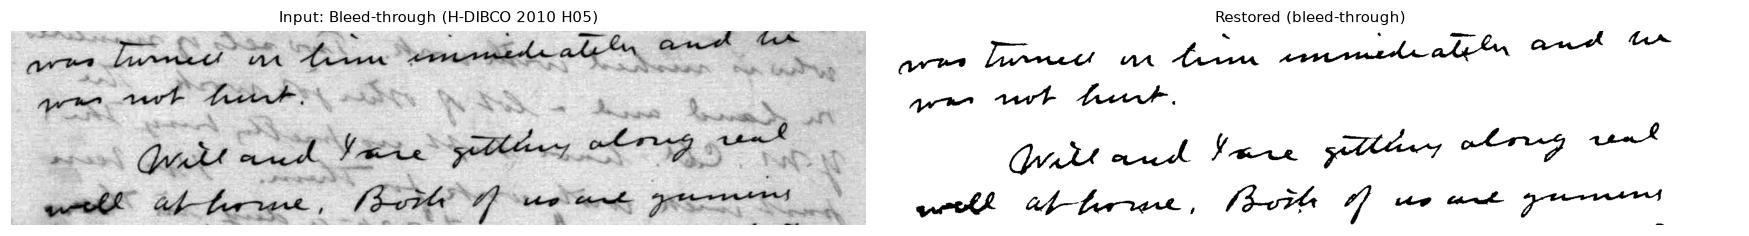

Unstained page
  -> detected: CLEAN
     stain         no   stained fraction = 0.000  (>= 0.05)
     blur          no   Laplacian reduction = 66.4%  (< 45.0%)   raw Laplacian var = 87.2
     bleed-through no   score = 0.032  (>= 0.1, credible=True, 128 components)
  -> method applied: none (no degradation detected)



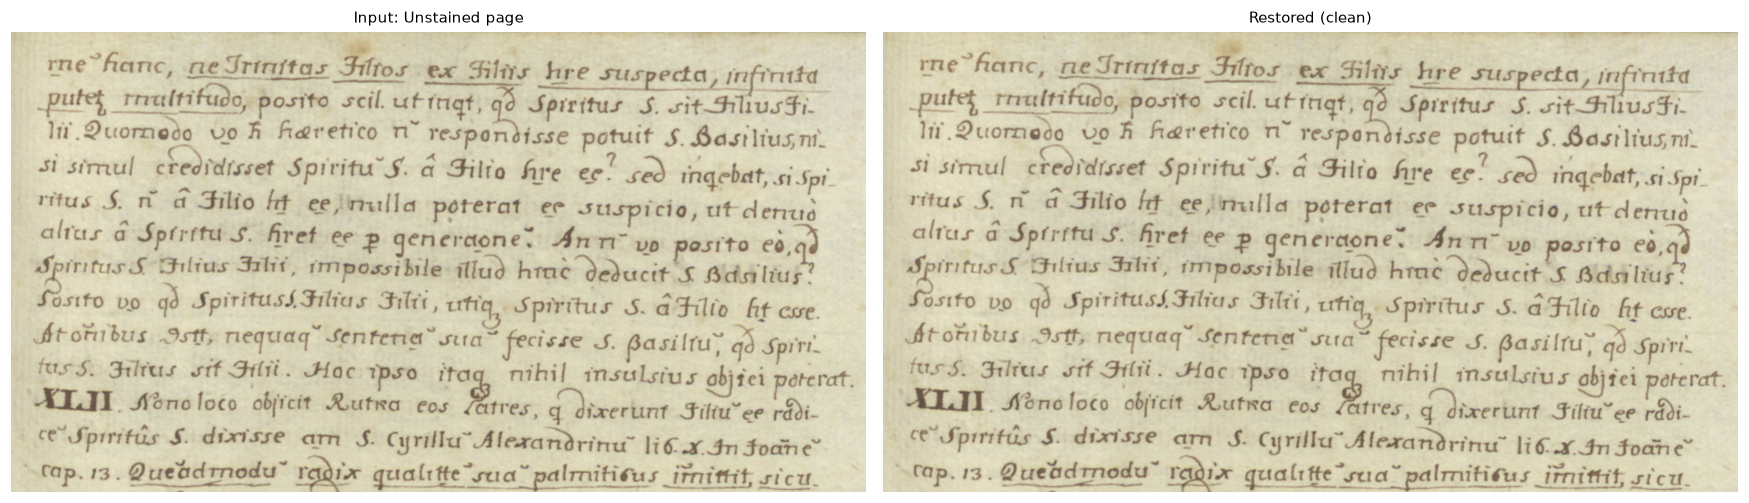

Unstained page, Gaussian blur sigma=3
  -> detected: BLUR
     stain         no   stained fraction = 0.000  (>= 0.05)
     blur          YES  Laplacian reduction = 13.4%  (< 45.0%)   raw Laplacian var = 3.5
     bleed-through YES  score = 0.141  (>= 0.1, credible=True, 425 components)
  -> method applied: Unsharp masking (strength 3.0, sigma 2.5)



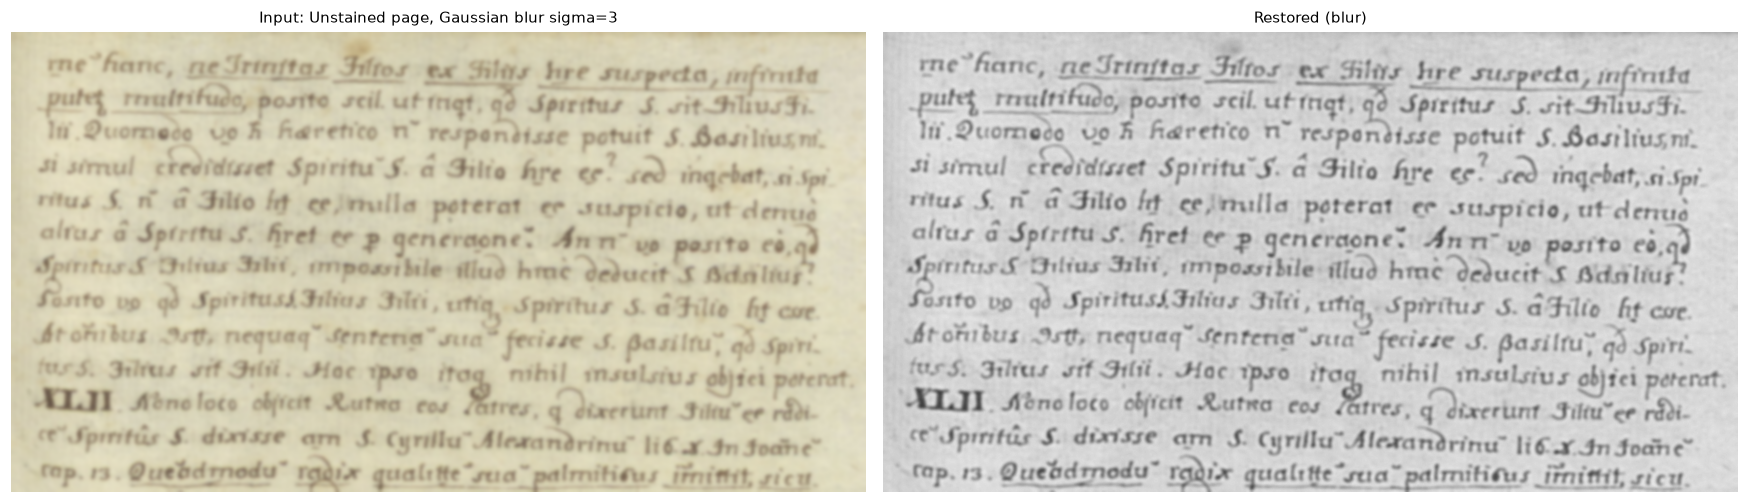

In [13]:
demo = {
    'Stained folio (folio212)': load_image('Sam/StainImages/Zoernikav folio212.jpg'),
    'Bleed-through (H-DIBCO 2010 H05)': load_image('Sam/StainImages/H05.png'),
    'Unstained page': load_image('Sam/StainImages/notstainedimageZoernikav.jpeg'),
}
demo['Unstained page, Gaussian blur sigma=3'] = cv2.GaussianBlur(demo['Unstained page'], (0, 0), 3)

for name, img in demo.items():
    r = restore_document(img)
    print_report(name, r['classification'])
    print(f"  -> method applied: {r['method']}\n")
    show([img, r['output']], ['Input: ' + name, f"Restored ({r['classification']['label']})"], cols=2, width=16)

### Batch: every image in a folder

Set `BATCH_DIR` to classify and restore every image in a folder. A summary table is printed, and every output is saved to `OUT_DIR`. Use the `stain`, `blur %` and `bleed` columns to check the thresholds in section 5.

In [14]:
BATCH_DIR = 'Sam/StainImages'

paths = sorted(p for ext in ('*.jpg', '*.jpeg', '*.png', '*.tif', '*.tiff')
               for p in glob.glob(os.path.join(BATCH_DIR, ext))
               if not any(tag in p for tag in ('_processed', '_stainmask', '_stainoverlay', '_restored')))
print(f"{'image':38s} {'label':14s} {'stain':>7s} {'blur %':>7s} {'bleed':>7s}")
for p in paths:
    r = restore_document(load_image(p))
    c = r['classification']
    save_result(p, r)
    print(f"{os.path.basename(p)[:38]:38s} {c['label']:14s} {c['stain']['fraction']:7.3f} "
          f"{c['blur']['reduction_pct']:7.1f} {c['bleed']['score']:7.3f}")
print(f'\nSaved to {OUT_DIR}/')

image                                  label            stain  blur %   bleed
H05.png                                bleed-through    0.000    81.1   1.146
Test.jpeg                              clean            0.000    66.4   0.032
Zoernikav folio212.jpg                 stain            0.231    75.0   0.082
Zoernikav folio212r.jpg                stain            0.199    75.8   0.079
Zoernikav folio213.jpg                 stain            0.152    75.4   0.163
Zoernikav folio213r.jpg                stain            0.178    77.3   0.161
Zoernikav folio214.jpg                 stain            0.150    74.7   0.124
Zoernikav folio214r.jpg                stain            0.167    76.4   0.138
notstainedimageZoernikav.jpeg          clean            0.000    66.4   0.032

Saved to final_output/


### Blur checks (Mohit)

In [15]:
sharp_page = demo['Unstained page']
blur_detector_check(sharp_page, cutoff=THRESHOLDS['blur_max_reduction'])
print()
blur_psnr_check(sharp_page)

test                    reduction   raw var  blurred?
sharp                       66.4%      87.2  no
gaussian sigma=1            42.0%      29.3  YES
gaussian sigma=2            22.4%       8.3  YES
gaussian sigma=3             9.5%       3.3  YES
gaussian sigma=4             4.0%       2.0  YES
gaussian sigma=5             0.5%       1.6  YES
motion length=5             56.5%      41.3  no
motion length=10            57.9%      24.7  no
motion length=15            57.8%      19.0  no
motion length=20            57.0%      16.3  no
defocus radius=2            40.1%      26.5  YES
defocus radius=3            28.4%      12.7  YES
defocus radius=5            16.1%       4.2  YES
defocus radius=7             9.1%       2.4  YES

PSNR against the sharp page (Gaussian blur sigma=2.5):
  blurred input     27.25 dB
  unsharp           30.61 dB
  laplacian (1.5)   28.99 dB
  CLAHE + unsharp   20.04 dB
PSNR against the sharp page (Gaussian blur sigma=5):
  blurred input     23.25 dB
  unsharp  